# Freight rate analysis

Run this notebook from the `freight-rate-assessment` folder. Each function is in its own cell. The cells at the bottom call those functions and save the charts and files.

Deleting `outputs` or `scorer_results_calibrated` is fine. Running this notebook creates them again.

Run `model_training.ipynb` before the report cell if you want the Word report. The report uses the model charts from that notebook.

## Setup

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from docx import Document
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.shared import Inches, Pt

### Paths and settings

In [2]:
ROOT = Path.cwd()
if not (ROOT / "data" / "train_test.csv").exists():
    raise FileNotFoundError("Run this notebook from the freight-rate-assessment folder.")
DATA = ROOT / "data"
OUTPUT = ROOT / "outputs"
FIGURES = OUTPUT / "figures"
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

HOLDOUT_START = pd.Timestamp("2025-10-01")
EQUIPMENT_CODES = {"Dry Van": 0, "Reefer": 1, "Flatbed": 2}
CORE_FEATURES = [
    "distance", "log_distance", "weight_abs", "weight_missing", "weight_negative",
    "doy_sin", "doy_cos", "dow", "month", "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon", "equipment_code",
]
MARKET_FEATURES = ["market_index", "market_missing", "quote_signal"]
CATEGORICAL = ["equipment_code", "dow", "month"]
MODEL_PARAMS = dict(
    loss="absolute_error", learning_rate=0.06, max_iter=300, max_depth=8,
    min_samples_leaf=20, l2_regularization=0.1, random_state=42,
)
COLOR = "#064A56"
ACCENT = "#C46B4A"
LAG_FEATURES = ["rpm_lag_1", "rpm_lag_7"]
MATRIX_COLUMNS = [
    "distance", "weight_abs", "market_index", "quote_signal", "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon", "is_dry_van", "is_reefer", "is_flatbed", "dow", "month",
    "posted_rate", "rpm",
]
EXPECTED_ROWS = 12_000
EXPECTED_IDS = {f"TE-{index:06d}" for index in range(1, EXPECTED_ROWS + 1)}
DECEMBER_DATES = pd.date_range("2025-12-01", "2025-12-31", freq="D")
FIXED_PICKUP = "Lexington"
FIXED_DELIVERY = "Fort Wayne"
FIXED_DISTANCE = 360.0
FIXED_EQUIPMENT = "Dry Van"
FIXED_WEIGHT = 32_000.0

## Feature engineering

### `regression_metrics`

In [3]:
def regression_metrics(actual: np.ndarray, predicted: np.ndarray) -> dict[str, float]:
    error = predicted - actual
    absolute = np.abs(error)
    percent = absolute / actual
    return {
        "mae": float(np.mean(absolute)),
        "rmse": float(np.sqrt(np.mean(error**2))),
        "mape": float(np.mean(percent)),
        "median_ae": float(np.median(absolute)),
        "r2": float(r2_score(actual, predicted)),
        "pct_over_25": float(np.mean(percent > 0.25)),
        "pct_over_50": float(np.mean(percent > 0.50)),
    }

### `city_coordinates`

In [4]:
def city_coordinates(labeled: pd.DataFrame) -> pd.DataFrame:
    pickup = labeled[["pickup", "pickup_lat", "pickup_lon"]].rename(
        columns={"pickup": "city", "pickup_lat": "lat", "pickup_lon": "lon"}
    )
    delivery = labeled[["delivery", "delivery_lat", "delivery_lon"]].rename(
        columns={"delivery": "city", "delivery_lat": "lat", "delivery_lon": "lon"}
    )
    coordinates = pd.concat([pickup, delivery], ignore_index=True).drop_duplicates()
    if coordinates["city"].duplicated().any():
        raise ValueError("a city has more than one coordinate pair")
    return coordinates

### `add_features`

In [5]:
def add_features(frame: pd.DataFrame, coordinates: pd.DataFrame | None = None) -> pd.DataFrame:
    features = frame.copy()
    features["date"] = pd.to_datetime(features["date"])
    if "pickup_lat" not in features.columns:
        if coordinates is None:
            raise ValueError("city coordinates are required when lat/lon are absent")
        features = features.merge(coordinates, left_on="pickup", right_on="city", how="left")
        features = features.rename(columns={"lat": "pickup_lat", "lon": "pickup_lon"}).drop(columns="city")
        features = features.merge(coordinates, left_on="delivery", right_on="city", how="left")
        features = features.rename(columns={"lat": "delivery_lat", "lon": "delivery_lon"}).drop(columns="city")
        if features[["pickup_lat", "delivery_lat"]].isna().any().any():
            raise ValueError("December cities are missing from the labeled coordinate table")

    weight = pd.to_numeric(features["weight"], errors="coerce")
    features["weight_missing"] = weight.isna().astype(np.int8)
    features["weight_negative"] = (weight < 0).fillna(False).astype(np.int8)
    features["weight_abs"] = weight.abs()

    if "market_index" not in features.columns:
        features["market_index"] = np.nan
    if "quote_signal" not in features.columns:
        features["quote_signal"] = np.nan
    features["market_missing"] = features["market_index"].isna().astype(np.int8)

    day_of_year = features["date"].dt.dayofyear.astype(float)
    features["doy_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
    features["doy_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)
    features["dow"] = features["date"].dt.dayofweek.astype(np.int8)
    features["month"] = features["date"].dt.month.astype(np.int8)
    features["log_distance"] = np.log(features["distance"].astype(float))
    unknown = set(features["equipment"].unique()) - set(EQUIPMENT_CODES)
    if unknown:
        raise ValueError(f"unexpected equipment types: {sorted(unknown)}")
    features["equipment_code"] = features["equipment"].map(EQUIPMENT_CODES).astype(np.int8)
    return features

### `make_model`

In [6]:
def make_model() -> HistGradientBoostingRegressor:
    return HistGradientBoostingRegressor(categorical_features=CATEGORICAL, **MODEL_PARAMS)

### `predict_rate`

In [7]:
def predict_rate(model: HistGradientBoostingRegressor, features: pd.DataFrame, columns: list[str]) -> np.ndarray:
    rate_per_mile = np.clip(model.predict(features[columns]), 0.05, None)
    return np.round(rate_per_mile * features["distance"].to_numpy(dtype=float), 2)

### `style_axis`

In [8]:
def style_axis(axis: plt.Axes) -> None:
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["left", "bottom"]].set_color("#9DAFB3")
    axis.grid(axis="y", color="#D9E2E4", linewidth=0.8)
    axis.set_axisbelow(True)

### `save`

In [9]:
def save(figure: plt.Figure, name: str) -> None:
    FIGURES.mkdir(parents=True, exist_ok=True)
    figure.tight_layout()
    figure.savefig(FIGURES / name, dpi=160, bbox_inches="tight")
    plt.close(figure)
    display(Image(filename=str(FIGURES / name)))

### `prepare`

In [10]:
def prepare() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    labeled = add_features(pd.read_csv(DATA / "train_test.csv"))
    labeled["rpm"] = labeled["posted_rate"] / labeled["distance"]
    labeled["is_dry_van"] = labeled["equipment"].eq("Dry Van").astype(float)
    labeled["is_reefer"] = labeled["equipment"].eq("Reefer").astype(float)
    labeled["is_flatbed"] = labeled["equipment"].eq("Flatbed").astype(float)
    fit = labeled.loc[labeled["date"] < HOLDOUT_START].copy()
    holdout = labeled.loc[labeled["date"] >= HOLDOUT_START].copy()
    return labeled, fit, holdout

## What affects the target

### `correlation_charts`

In [11]:
def correlation_charts(labeled: pd.DataFrame) -> pd.DataFrame:
    matrix = labeled[MATRIX_COLUMNS].corr(method="pearson")
    labels = [
        "distance",
        "weight",
        "market index",
        "quote signal",
        "pickup lat",
        "pickup lon",
        "delivery lat",
        "delivery lon",
        "dry van",
        "reefer",
        "flatbed",
        "weekday",
        "month",
        "posted rate",
        "rate per mile",
    ]
    figure, axis = plt.subplots(figsize=(11.2, 9.2))
    image = axis.imshow(matrix.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
    axis.set_xticks(range(len(labels)), labels, rotation=55, ha="right")
    axis.set_yticks(range(len(labels)), labels)
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = matrix.iloc[row, column]
            axis.text(
                column,
                row,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if abs(value) > 0.55 else "#1F2A2E",
            )
    axis.set_title("Correlation matrix", loc="left", fontsize=15, fontweight="bold", pad=12)
    figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
    save(figure, "correlation_matrix.png")

    target = matrix["posted_rate"].drop(labels=["posted_rate", "rpm"]).sort_values(key=np.abs)
    per_mile = matrix["rpm"].drop(labels=["posted_rate", "rpm"]).reindex(target.index)
    figure, axis = plt.subplots(figsize=(10.2, 6.2))
    positions = np.arange(len(target))
    axis.barh(positions - 0.18, target.to_numpy(), height=0.36, color=COLOR, label="with posted rate ($)")
    axis.barh(positions + 0.18, per_mile.to_numpy(), height=0.36, color=ACCENT, label="with rate per mile")
    axis.set_yticks(positions, target.index.map(dict(zip(MATRIX_COLUMNS, labels))))
    axis.axvline(0, color="#9DAFB3", linewidth=0.8)
    axis.set_xlabel("Pearson correlation")
    axis.set_title("What moves the target, and what does not", loc="left", fontsize=15, fontweight="bold")
    axis.legend(frameon=False)
    style_axis(axis)
    save(figure, "target_correlations.png")
    matrix.to_csv(FIGURES / "correlation_matrix.csv")
    return matrix

### `driver_charts`

In [12]:
def driver_charts(labeled: pd.DataFrame) -> None:
    sample = labeled.sample(n=4000, random_state=42)
    figure, axis = plt.subplots(figsize=(8.4, 5.2))
    axis.scatter(sample["distance"], sample["posted_rate"], s=8, alpha=0.25, color=COLOR, linewidths=0)
    axis.set_xlabel("Distance (miles)")
    axis.set_ylabel("Posted rate ($)")
    axis.set_title("Posted rate rises with distance", loc="left", fontsize=15, fontweight="bold")
    style_axis(axis)
    save(figure, "distance_vs_rate.png")

    figure, axis = plt.subplots(figsize=(7.4, 4.8))
    order = ["Dry Van", "Flatbed", "Reefer"]
    data = [labeled.loc[labeled["equipment"].eq(name), "rpm"] for name in order]
    box = axis.boxplot(data, tick_labels=order, showfliers=False, patch_artist=True)
    for patch in box["boxes"]:
        patch.set_facecolor("#D7E6E8")
        patch.set_edgecolor(COLOR)
    axis.set_ylabel("Rate per mile ($)")
    axis.set_title("Equipment shifts rate per mile", loc="left", fontsize=15, fontweight="bold")
    style_axis(axis)
    save(figure, "equipment_vs_rpm.png")

    monthly = labeled.groupby(labeled["date"].dt.month)["rpm"].median()
    figure, axis = plt.subplots(figsize=(8.2, 4.6))
    axis.plot(monthly.index, monthly.to_numpy(), color=COLOR, marker="o", linewidth=2.2)
    axis.set_xticks(range(1, 11))
    axis.set_xlabel("Month in 2025")
    axis.set_ylabel("Median rate per mile ($)")
    axis.set_title("Seasonal level of rate per mile", loc="left", fontsize=15, fontweight="bold")
    style_axis(axis)
    save(figure, "rpm_by_month.png")

    weekly = labeled.groupby("dow")["rpm"].median()
    figure, axis = plt.subplots(figsize=(8.2, 4.6))
    axis.bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], weekly.to_numpy(), color=COLOR)
    axis.set_ylabel("Median rate per mile ($)")
    axis.set_title("Weekday level of rate per mile", loc="left", fontsize=15, fontweight="bold")
    style_axis(axis)
    save(figure, "rpm_by_weekday.png")

    known_weight = labeled.dropna(subset=["weight_abs"])
    bins = pd.qcut(known_weight["weight_abs"], 8)
    weight_rpm = known_weight.groupby(bins, observed=True)["rpm"].median()
    figure, axis = plt.subplots(figsize=(8.6, 4.6))
    axis.plot(range(len(weight_rpm)), weight_rpm.to_numpy(), color=COLOR, marker="o", linewidth=2.2)
    axis.set_xticks(range(len(weight_rpm)), [str(interval) for interval in weight_rpm.index], rotation=30, ha="right")
    axis.set_ylabel("Median rate per mile ($)")
    axis.set_xlabel("Absolute weight bin (lb)")
    axis.set_title("Heavier loads cost a little more per mile", loc="left", fontsize=15, fontweight="bold")
    style_axis(axis)
    save(figure, "weight_vs_rpm.png")

## Run the charts

training rows 43,147
October rows  4,853


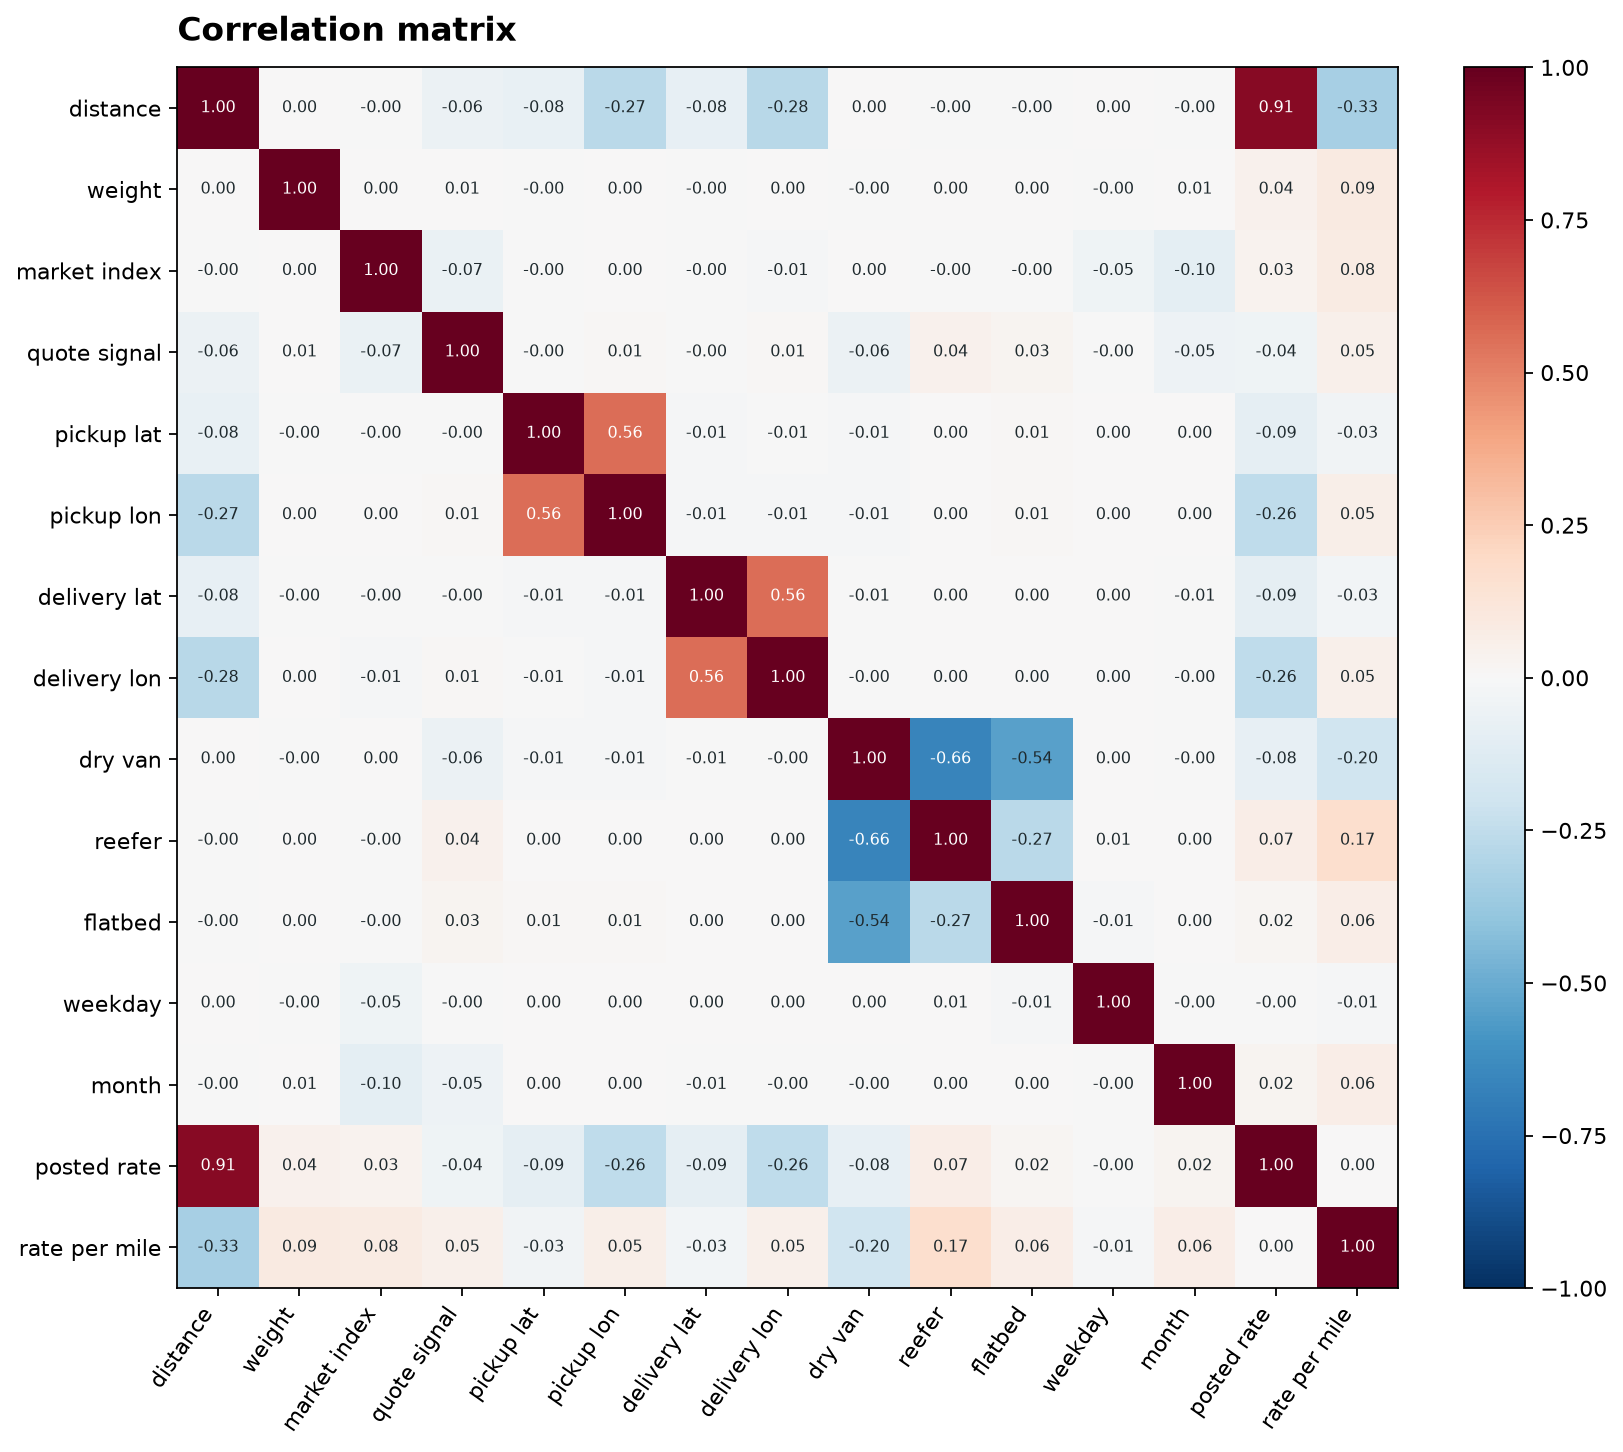

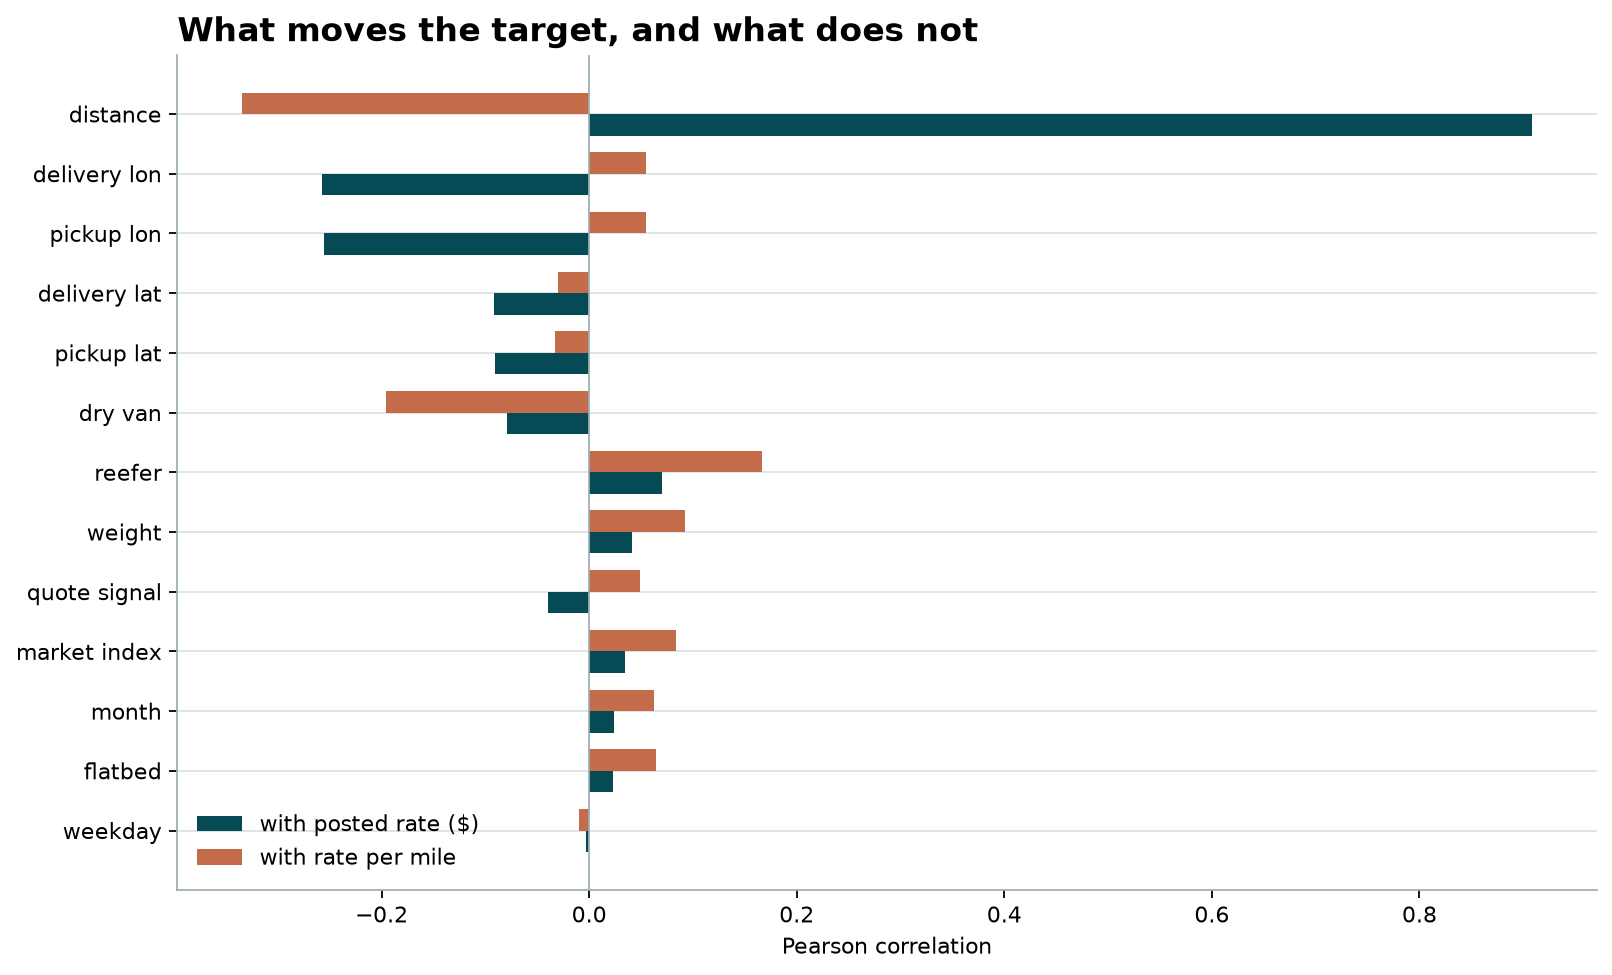

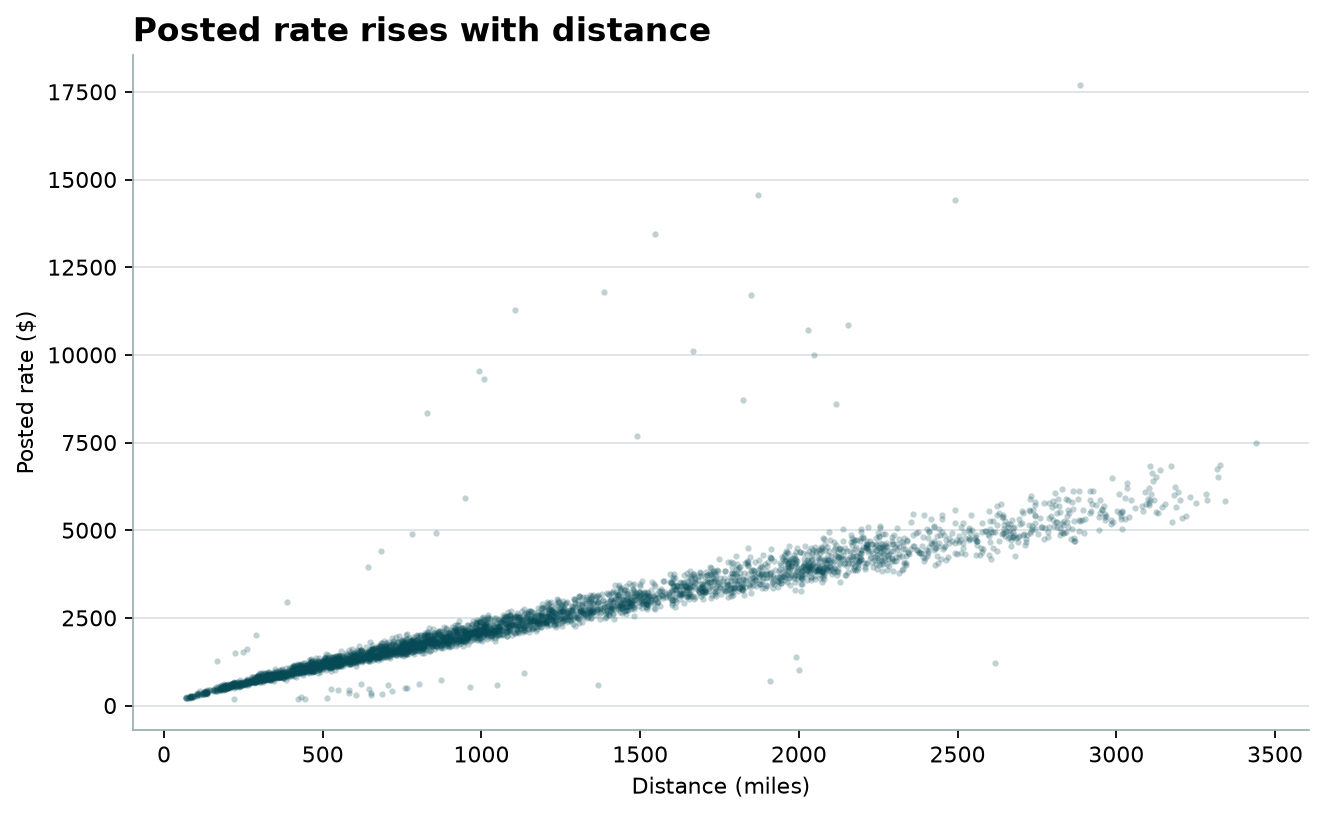

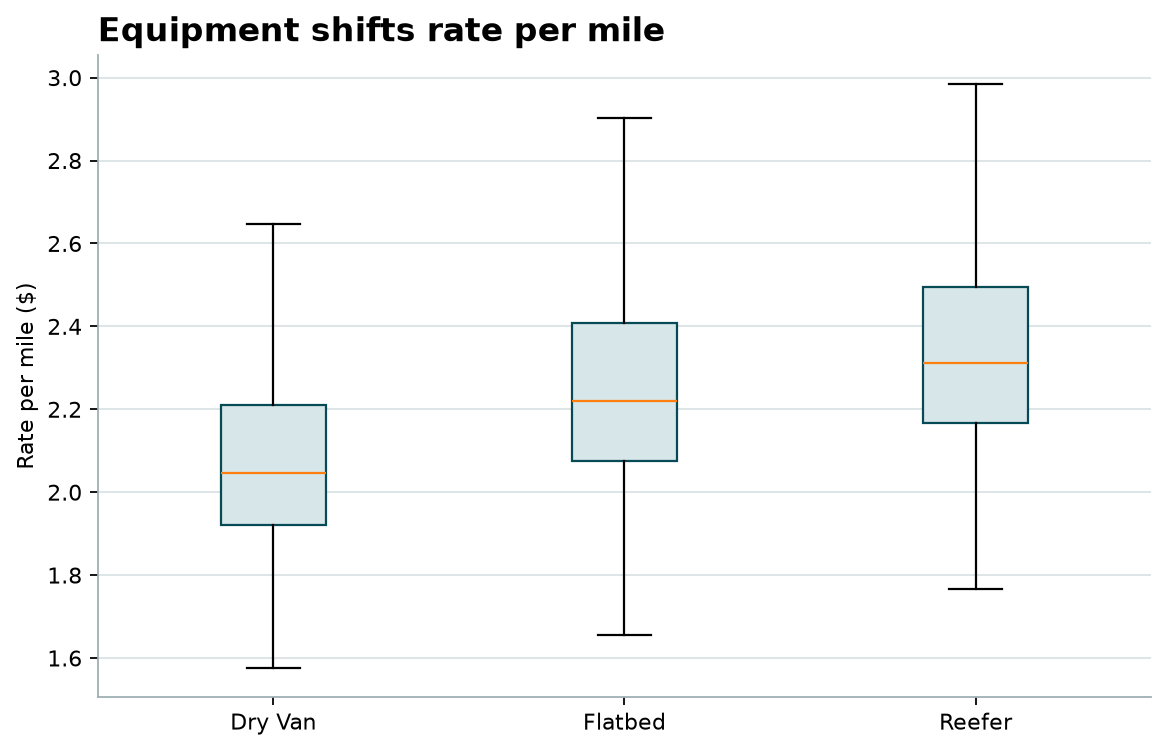

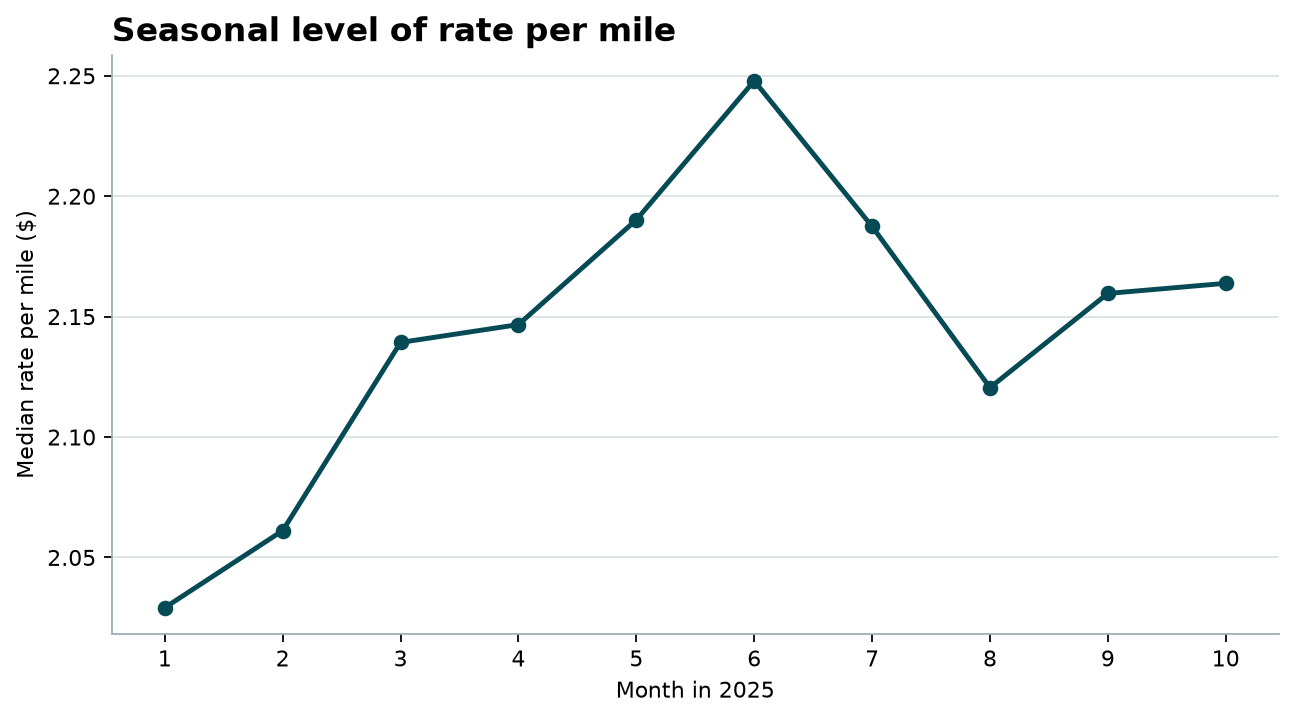

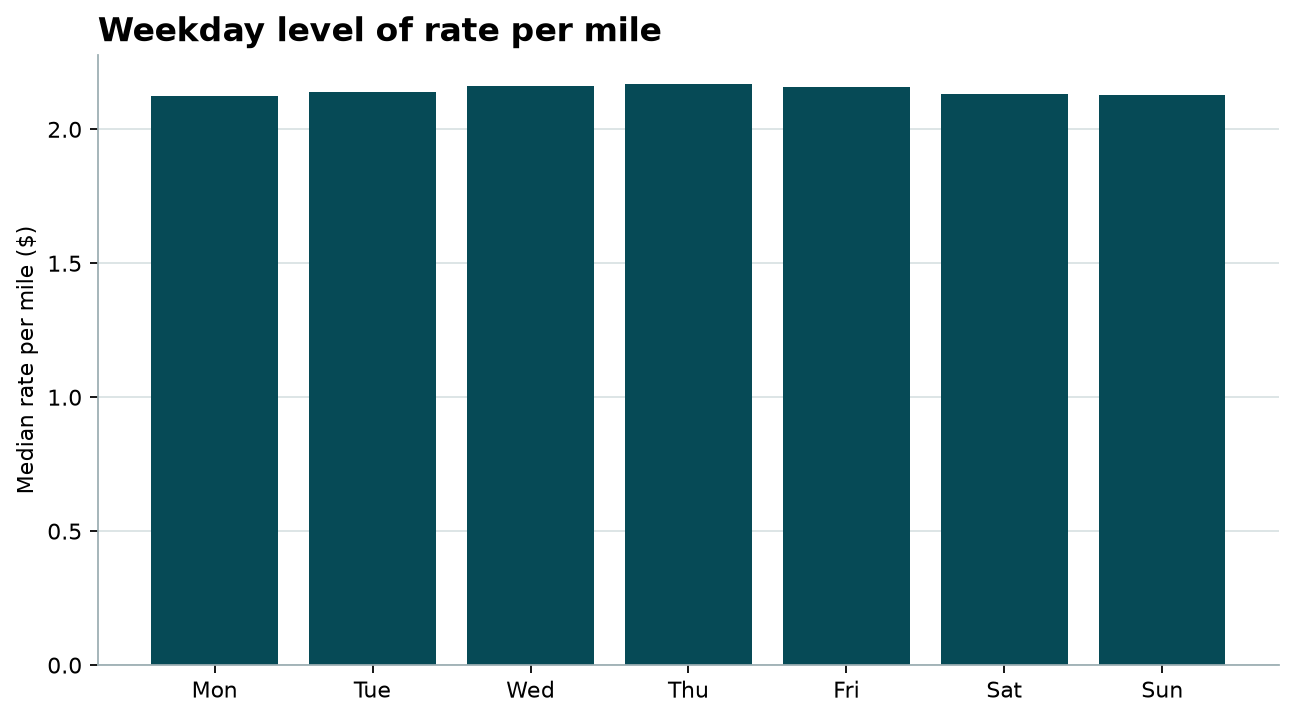

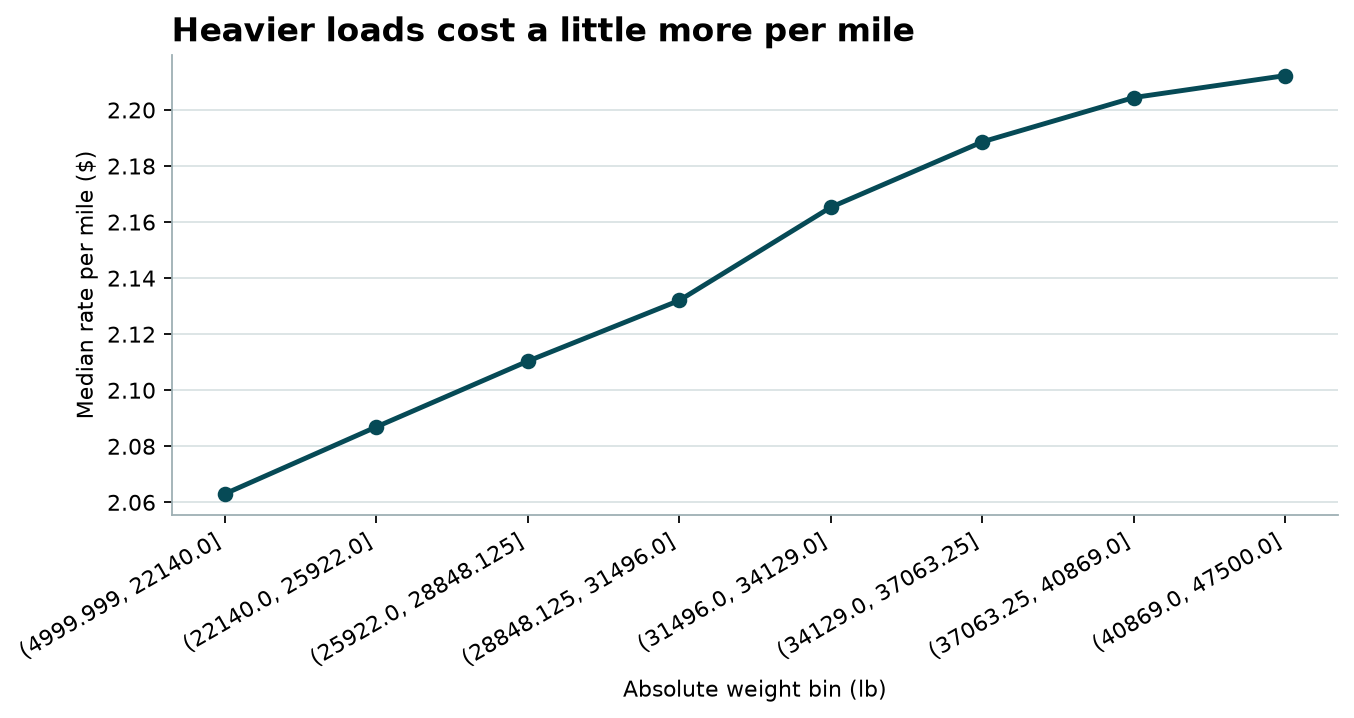

posted_rate     1.000
distance        0.909
delivery_lon   -0.257
pickup_lon     -0.255
delivery_lat   -0.092
pickup_lat     -0.091
is_dry_van     -0.079
is_reefer       0.070
weight_abs      0.041
quote_signal   -0.040
market_index    0.034
month           0.024
is_flatbed      0.023
dow            -0.003
rpm             0.003
Name: posted_rate, dtype: float64


In [13]:
labeled, fit, holdout = prepare()
print(f'training rows {len(fit):,}')
print(f'October rows  {len(holdout):,}')
correlation = correlation_charts(labeled)
driver_charts(labeled)
print(correlation['posted_rate'].sort_values(key=lambda s: s.abs(), ascending=False).round(3))

## Overfit and underfit check

### `fit_depth_model`

In [14]:
def fit_depth_model(frame: pd.DataFrame, **overrides: object) -> HistGradientBoostingRegressor:
    params = {**MODEL_PARAMS, **overrides}
    model = HistGradientBoostingRegressor(categorical_features=CATEGORICAL, **params)
    model.fit(frame[CORE_FEATURES], frame["posted_rate"] / frame["distance"])
    return model

### `score_holdout`

In [15]:
def score_holdout(model: HistGradientBoostingRegressor, frame: pd.DataFrame) -> dict[str, float]:
    predicted = predict_rate(model, frame, CORE_FEATURES)
    return regression_metrics(frame["posted_rate"].to_numpy(dtype=float), predicted)

### `run_fit_check`

In [16]:
def run_fit_check() -> None:
    labeled = add_features(pd.read_csv(DATA / "train_test.csv"))
    leaked = set(CORE_FEATURES) & {"posted_rate", "rpm"}
    if leaked:
        raise ValueError(f"target columns leaked into features: {sorted(leaked)}")
    fit = labeled.loc[labeled["date"] < HOLDOUT_START].copy()
    holdout = labeled.loc[labeled["date"] >= HOLDOUT_START].copy()
    if fit["date"].max() >= HOLDOUT_START or holdout["date"].min() < HOLDOUT_START:
        raise ValueError("the October split is mixed")

    production = fit_depth_model(fit)
    train_metrics = score_holdout(production, fit)
    october_metrics = score_holdout(production, holdout)
    print(
        f"production train MAE {train_metrics['mae']:.2f}  "
        f"October MAE {october_metrics['mae']:.2f}  "
        f"gap {october_metrics['mae'] - train_metrics['mae']:.2f}"
    )

    memorized = fit_depth_model(fit, max_depth=20, min_samples_leaf=1, l2_regularization=0.0)
    memorized_train = score_holdout(memorized, fit)
    memorized_october = score_holdout(memorized, holdout)
    print(
        f"unrestricted train MAE {memorized_train['mae']:.2f}  "
        f"October MAE {memorized_october['mae']:.2f}"
    )

    depths = [2, 4, 6, 8, 12, 16]
    depth_rows = []
    for depth in depths:
        if depth == MODEL_PARAMS["max_depth"]:
            model = production
            train_row, october_row = train_metrics, october_metrics
        else:
            model = fit_depth_model(fit, max_depth=depth)
            train_row, october_row = score_holdout(model, fit), score_holdout(model, holdout)
        depth_rows.append({"max_depth": depth, "train": train_row, "october": october_row})
        print(f"depth {depth:2}  train {train_row['mae']:.2f}  october {october_row['mae']:.2f}")

    forward_rows = []
    for month in range(4, 11):
        start = pd.Timestamp(year=2025, month=month, day=1)
        end = start + pd.offsets.MonthEnd(0)
        train = labeled.loc[labeled["date"] < start]
        test = labeled.loc[(labeled["date"] >= start) & (labeled["date"] <= end)]
        model = production if month == 10 else fit_depth_model(train)
        train_row = train_metrics if month == 10 else score_holdout(model, train)
        test_row = october_metrics if month == 10 else score_holdout(model, test)
        forward_rows.append(
            {
                "test_month": f"2025-{month:02d}",
                "train_rows": int(len(train)),
                "test_rows": int(len(test)),
                "train_mae": train_row["mae"],
                "test_mae": test_row["mae"],
                "train_mape": train_row["mape"],
                "test_mape": test_row["mape"],
            }
        )
        print(f"{start:%Y-%m}  train MAE {train_row['mae']:.2f}  next-month MAE {test_row['mae']:.2f}")

    october_prediction = predict_rate(production, holdout, CORE_FEATURES)
    residual = october_prediction - holdout["posted_rate"].to_numpy(dtype=float)
    distance_bin = pd.qcut(holdout["distance"], 5)
    by_distance = (
        pd.DataFrame({"bin": distance_bin, "absolute_error": np.abs(residual)})
        .groupby("bin", observed=True)["absolute_error"]
        .mean()
    )

    figure, axis = plt.subplots(figsize=(8.2, 4.8))
    labels = ["Training\nJan-Sep", "October\nholdout", "Unrestricted tree\nOctober"]
    values = [train_metrics["mae"], october_metrics["mae"], memorized_october["mae"]]
    axis.bar(labels, values, color=[COLOR, ACCENT, "#8AA4A8"])
    axis.set_ylabel("MAE ($)")
    axis.set_title("Training error versus October error", loc="left", fontsize=15, fontweight="bold")
    style_axis(axis)
    save(figure, "train_vs_october.png")

    figure, axis = plt.subplots(figsize=(8.2, 4.8))
    axis.plot(depths, [row["train"]["mae"] for row in depth_rows], marker="o", color=COLOR, label="Training MAE")
    axis.plot(depths, [row["october"]["mae"] for row in depth_rows], marker="o", color=ACCENT, label="October MAE")
    axis.axvline(MODEL_PARAMS["max_depth"], color="#9DAFB3", linestyle="--", linewidth=1)
    axis.set_xlabel("Tree depth")
    axis.set_ylabel("MAE ($)")
    axis.set_title("Error by model complexity", loc="left", fontsize=15, fontweight="bold")
    axis.legend(frameon=False)
    style_axis(axis)
    save(figure, "complexity_curve.png")

    figure, axis = plt.subplots(figsize=(8.6, 4.8))
    months = [row["test_month"] for row in forward_rows]
    axis.plot(months, [row["train_mae"] for row in forward_rows], marker="o", color=COLOR, label="Training MAE")
    axis.plot(months, [row["test_mae"] for row in forward_rows], marker="o", color=ACCENT, label="Next-month MAE")
    axis.set_ylabel("MAE ($)")
    axis.set_title("Forward test: train through the previous month", loc="left", fontsize=15, fontweight="bold")
    axis.legend(frameon=False)
    style_axis(axis)
    save(figure, "forward_month_error.png")

    figure, axis = plt.subplots(figsize=(8.2, 4.8))
    axis.bar([str(interval) for interval in by_distance.index], by_distance.to_numpy(), color=COLOR)
    axis.tick_params(axis="x", rotation=25)
    axis.set_ylabel("October MAE ($)")
    axis.set_xlabel("Distance bin (miles)")
    axis.set_title("October error grows with trip length", loc="left", fontsize=15, fontweight="bold")
    style_axis(axis)
    save(figure, "october_error_by_distance.png")

    best_depth = min(depth_rows, key=lambda row: row["october"]["mae"])
    payload = {
        "production_train": train_metrics,
        "production_october": october_metrics,
        "mae_gap": october_metrics["mae"] - train_metrics["mae"],
        "mape_gap": october_metrics["mape"] - train_metrics["mape"],
        "unrestricted_train": memorized_train,
        "unrestricted_october": memorized_october,
        "depth_curve": depth_rows,
        "best_october_depth": best_depth["max_depth"],
        "forward_months": forward_rows,
        "october_mae_by_distance": {str(key): float(value) for key, value in by_distance.items()},
        "october_residual_median": float(np.median(residual)),
        "features_exclude_target": True,
    }
    output = ROOT / "outputs" / "fit_diagnostics.json"
    output.write_text(json.dumps(payload, indent=2), encoding="utf-8")
    print(f"Wrote {output}")

## Run the fit check

production train MAE 80.65  October MAE 115.50  gap 34.84
unrestricted train MAE 80.51  October MAE 116.26
depth  2  train 88.37  october 113.91
depth  4  train 82.88  october 116.82
depth  6  train 80.75  october 115.85
depth  8  train 80.65  october 115.50
depth 12  train 80.54  october 116.97
depth 16  train 80.50  october 116.54
2025-04  train MAE 72.93  next-month MAE 112.20
2025-05  train MAE 73.46  next-month MAE 101.17
2025-06  train MAE 74.55  next-month MAE 151.42
2025-07  train MAE 78.27  next-month MAE 140.57
2025-08  train MAE 79.66  next-month MAE 90.03
2025-09  train MAE 80.11  next-month MAE 97.18
2025-10  train MAE 80.65  next-month MAE 115.50


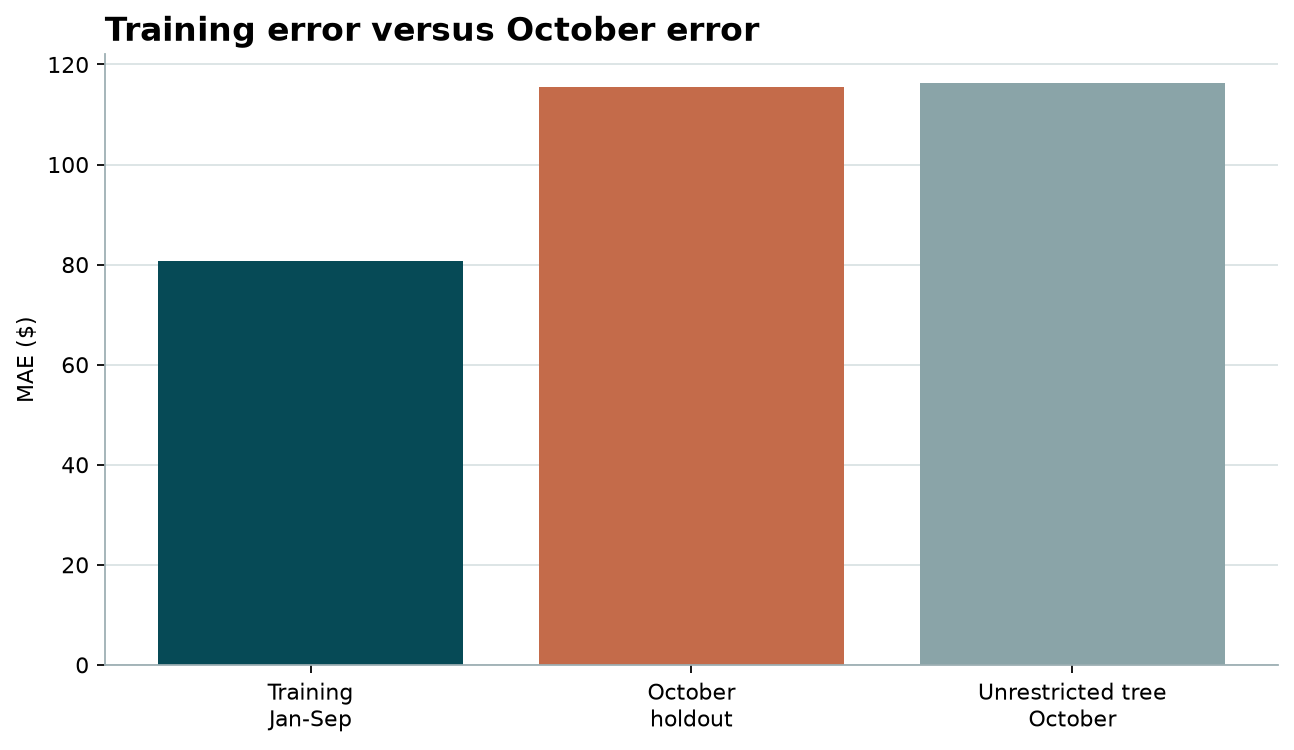

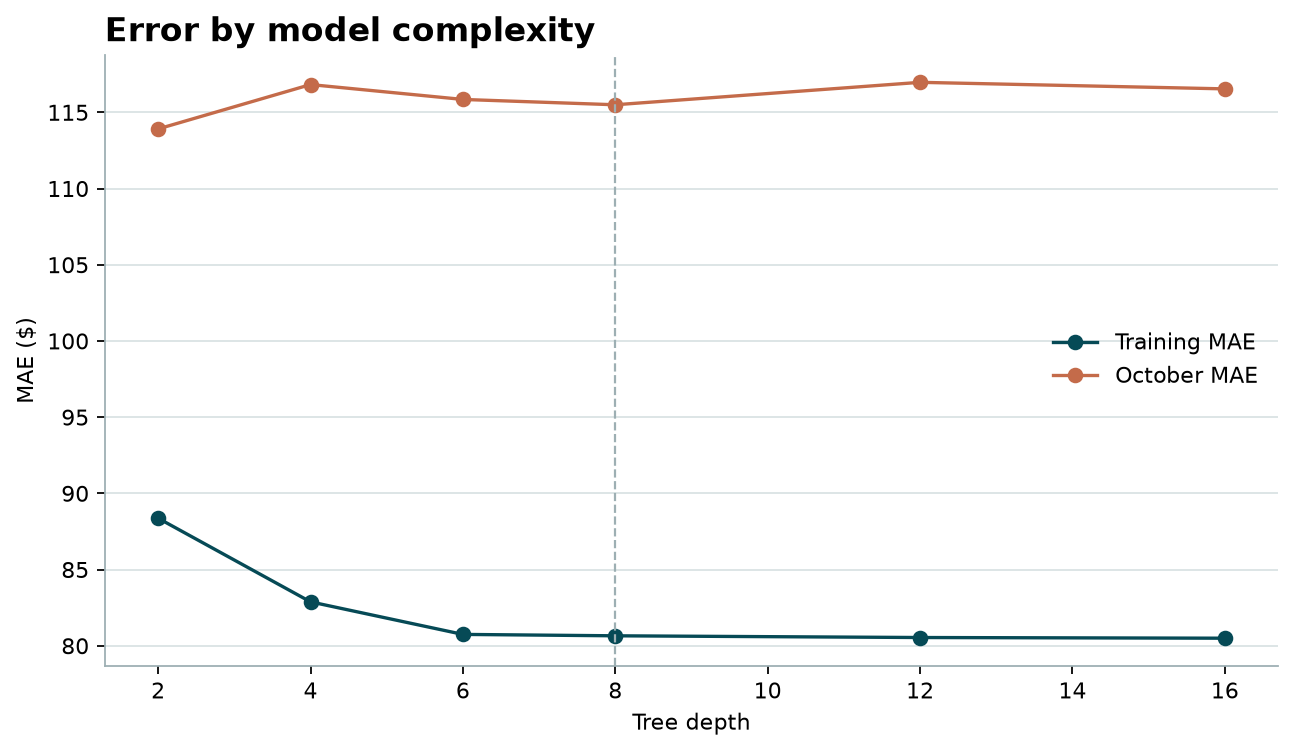

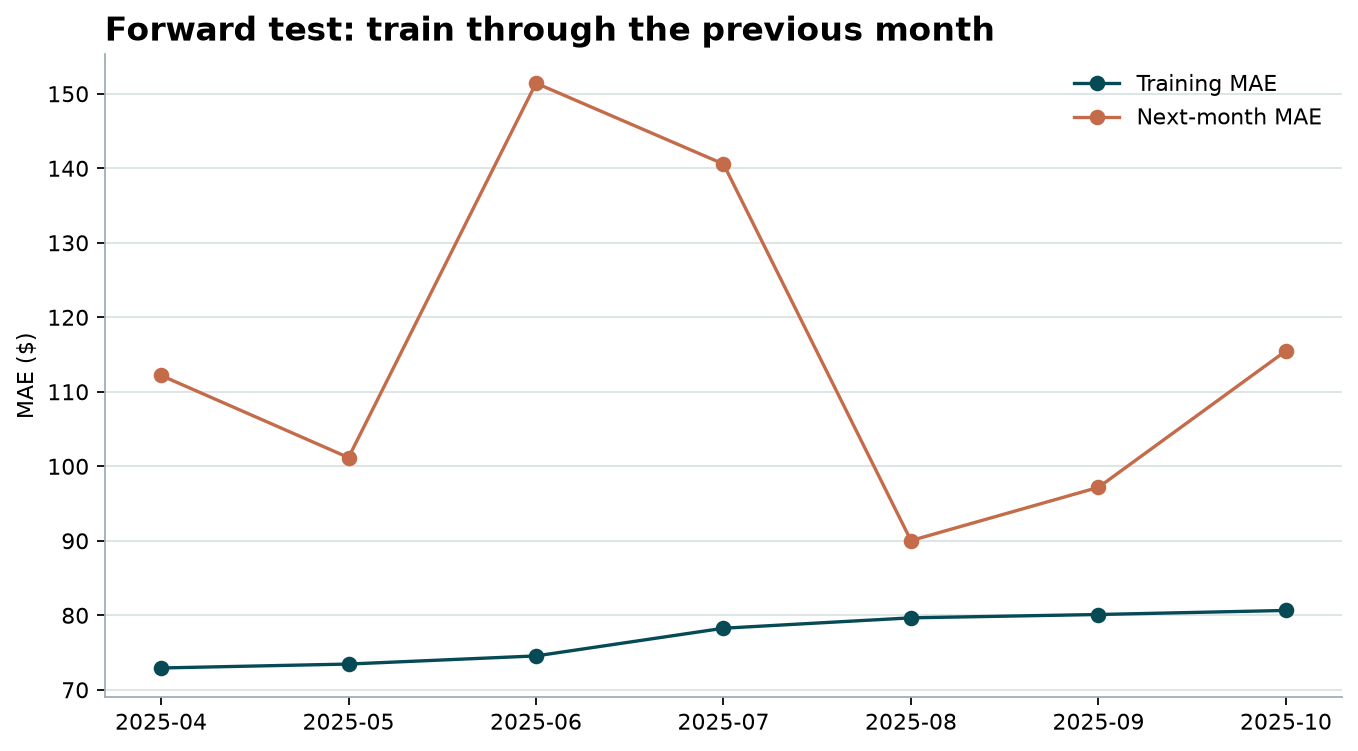

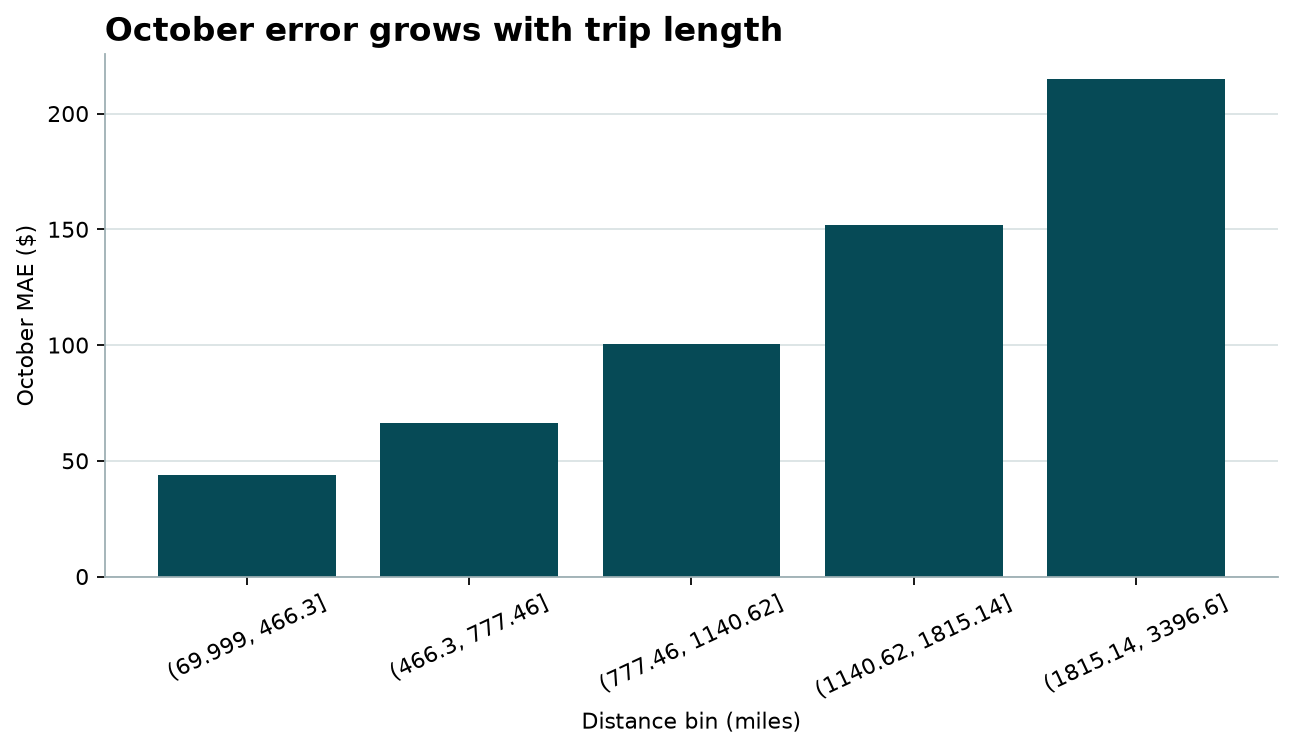

Wrote d:\projects\SchoolProject\freight-rate-assessment\outputs\fit_diagnostics.json


In [17]:
run_fit_check()

## Lags and 14-day calibration

### `load_labeled`

In [18]:
def load_labeled() -> pd.DataFrame:
    labeled = add_features(pd.read_csv(DATA / "train_test.csv"))
    labeled["rpm"] = labeled["posted_rate"] / labeled["distance"]
    return labeled

### `fit_feature_model`

In [19]:
def fit_feature_model(frame: pd.DataFrame, columns: list[str]):

    model = make_model()
    model.fit(frame[columns], frame["rpm"])
    return model

### `dollar_rates`

In [20]:
def dollar_rates(model, frame: pd.DataFrame, columns: list[str], factor: float = 1.0) -> np.ndarray:
    rate_per_mile = np.clip(model.predict(frame[columns]), 0.05, None) * factor
    return np.round(rate_per_mile * frame["distance"].to_numpy(dtype=float), 2)

### `daily_rpm`

In [21]:
def daily_rpm(frame: pd.DataFrame) -> pd.Series:
    daily = frame.groupby(frame["date"].dt.normalize())["rpm"].median().sort_index()
    daily = daily.asfreq("D")
    if daily.isna().any():
        raise ValueError("daily rate per mile has a gap")
    return daily

### `attach_lags`

In [22]:
def attach_lags(frame: pd.DataFrame, history: pd.DataFrame) -> pd.DataFrame:
    """Past-only lags. Dates after the history keep the last known market level."""
    daily = daily_rpm(history)
    lag_1 = daily.shift(1)
    lag_7 = daily.shift(1).rolling(7, min_periods=3).median()
    last = daily.index.max()
    frozen_1 = float(daily.loc[last])
    frozen_7 = float(daily.iloc[-7:].median())
    dates = frame["date"].dt.normalize()
    out = frame.copy()
    out["rpm_lag_1"] = dates.map(lag_1)
    out["rpm_lag_7"] = dates.map(lag_7)
    after = dates > last
    out.loc[after, "rpm_lag_1"] = frozen_1
    out.loc[after, "rpm_lag_7"] = frozen_7
    return out

### `month_slices`

In [23]:
def month_slices(labeled: pd.DataFrame, month: int) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    start = pd.Timestamp(year=2025, month=month, day=1)
    end = start + pd.offsets.MonthEnd(0)
    calib_start = start - pd.Timedelta(days=14)
    test = labeled.loc[(labeled["date"] >= start) & (labeled["date"] <= end)].copy()
    calib = labeled.loc[(labeled["date"] >= calib_start) & (labeled["date"] < start)].copy()
    train = labeled.loc[labeled["date"] < calib_start].copy()
    before = labeled.loc[labeled["date"] < start].copy()
    return train, calib, test, before

### `calibration_factor`

In [24]:
def calibration_factor(model, frame: pd.DataFrame, columns: list[str]) -> float:
    predicted = np.clip(model.predict(frame[columns]), 0.05, None)
    actual = frame["rpm"].to_numpy(dtype=float)
    return float(np.median(actual / predicted))

### `score_frame`

In [25]:
def score_frame(frame: pd.DataFrame, predicted: np.ndarray) -> dict[str, float]:
    return regression_metrics(frame["posted_rate"].to_numpy(dtype=float), predicted)

### `run_forward`

In [26]:
def run_forward() -> pd.DataFrame:
    labeled = load_labeled()
    rows = []
    for month in range(4, 11):
        train, calib, test, before = month_slices(labeled, month)
        current_model = fit_feature_model(before, CORE_FEATURES)
        current_pred = dollar_rates(current_model, test, CORE_FEATURES)
        current = score_frame(test, current_pred)

        lagged_before = attach_lags(before, before)
        lagged_test = attach_lags(test, before)
        lag_columns = CORE_FEATURES + LAG_FEATURES
        lag_model = fit_feature_model(lagged_before, lag_columns)
        lag_pred = dollar_rates(lag_model, lagged_test, lag_columns)
        lagged = score_frame(test, lag_pred)

        calib_model = fit_feature_model(train, CORE_FEATURES)
        factor = calibration_factor(calib_model, calib, CORE_FEATURES)
        calib_pred = dollar_rates(calib_model, test, CORE_FEATURES, factor)
        calibrated = score_frame(test, calib_pred)

        lagged_train = attach_lags(train, train)
        lagged_calib = attach_lags(calib, train)
        both_model = fit_feature_model(lagged_train, lag_columns)
        both_factor = calibration_factor(both_model, lagged_calib, lag_columns)
        both_test = attach_lags(test, before)
        both_pred = dollar_rates(both_model, both_test, lag_columns, both_factor)
        both = score_frame(test, both_pred)

        rows.append(
            {
                "month": f"2025-{month:02d}",
                "current_mae": current["mae"],
                "lag_mae": lagged["mae"],
                "calibration_mae": calibrated["mae"],
                "both_mae": both["mae"],
                "calibration_factor": factor,
                "both_factor": both_factor,
            }
        )
        print(
            f"2025-{month:02d}  current {current['mae']:.2f}  "
            f"lag {lagged['mae']:.2f}  calib {calibrated['mae']:.2f}  "
            f"both {both['mae']:.2f}  factor {factor:.3f}"
        )
    return pd.DataFrame(rows)

### `write_calibrated_predictions`

In [27]:
def write_calibrated_predictions() -> dict[str, float]:
    """Fit through 17 Oct, scale by 18-31 Oct, price November-December."""
    labeled = load_labeled()
    calib_start = pd.Timestamp("2025-10-18")
    train = labeled.loc[labeled["date"] < calib_start]
    calib = labeled.loc[labeled["date"] >= calib_start]
    model = fit_feature_model(train, CORE_FEATURES)
    factor = calibration_factor(model, calib, CORE_FEATURES)

    validation = add_features(pd.read_csv(DATA / "validation.csv"))
    coordinates = city_coordinates(pd.read_csv(DATA / "train_test.csv"))
    december = add_features(pd.read_csv(DATA / "december_chart_inputs.csv"), coordinates)
    validation_rates = dollar_rates(model, validation, CORE_FEATURES, factor)
    december_rates = dollar_rates(model, december, CORE_FEATURES, factor)

    template = pd.read_csv(DATA / "validation_predictions_template.csv")
    submitted = template[["load_id"]].merge(
        pd.DataFrame({"load_id": validation["load_id"], "predicted_rate": validation_rates}),
        on="load_id",
        how="left",
        validate="one_to_one",
    )
    december_output = pd.read_csv(DATA / "december_chart_inputs.csv")
    december_output["predicted_rate"] = december_rates
    submitted.to_csv(ROOT / "validation_predictions_calibrated.csv", index=False)
    december_output.to_csv(ROOT / "december_predictions_calibrated.csv", index=False)
    print(f"calibration factor {factor:.4f}")
    print(f"December ${december_rates.min():.2f} to ${december_rates.max():.2f}")
    return {"factor": factor, "december_min": float(december_rates.min()), "december_max": float(december_rates.max())}

### `run_enhancement`

In [28]:
def run_enhancement() -> None:
    table = run_forward()
    means = {
        "current": float(table["current_mae"].mean()),
        "lag": float(table["lag_mae"].mean()),
        "calibration": float(table["calibration_mae"].mean()),
        "both": float(table["both_mae"].mean()),
    }
    winner = min(means, key=means.get)
    payload = {"months": table.to_dict(orient="records"), "mean_mae": means, "winner": winner}
    output = ROOT / "outputs" / "enhancement.json"
    output.write_text(json.dumps(payload, indent=2), encoding="utf-8")
    print("mean MAE", {name: round(value, 2) for name, value in means.items()})
    print("winner", winner)
    summary = write_calibrated_predictions()
    payload["calibrated_submission"] = summary
    output.write_text(json.dumps(payload, indent=2), encoding="utf-8")
    print(f"Wrote {output}")

## Run the enhancement

In [29]:
run_enhancement()

2025-04  current 112.20  lag 108.07  calib 97.61  both 97.34  factor 1.024
2025-05  current 101.17  lag 91.24  calib 112.37  both 99.60  factor 1.022
2025-06  current 151.42  lag 141.74  calib 148.43  both 146.65  factor 1.007
2025-07  current 140.57  lag 146.23  calib 119.83  both 134.07  factor 1.019
2025-08  current 90.03  lag 86.53  calib 97.79  both 86.14  factor 0.983
2025-09  current 97.18  lag 101.73  calib 96.97  both 102.65  factor 0.998
2025-10  current 115.50  lag 109.58  calib 104.74  both 136.10  factor 1.021
mean MAE {'current': 115.44, 'lag': 112.16, 'calibration': 111.11, 'both': 114.65}
winner calibration
calibration factor 1.0217
December $811.10 to $837.97
Wrote d:\projects\SchoolProject\freight-rate-assessment\outputs\enhancement.json


## Checker for the calibrated files

### `fail`

In [30]:
def fail(message: str) -> None:
    raise SystemExit(f"ERROR: {message}")

### `read_csv`

In [31]:
def read_csv(path: Path, label: str) -> pd.DataFrame:
    if not path.is_file():
        fail(f"{label} file not found: {path}")
    try:
        return pd.read_csv(path)
    except Exception as exc:
        fail(f"could not read {label}: {exc}")

### `numeric_series`

In [32]:
def numeric_series(frame: pd.DataFrame, column: str, label: str) -> pd.Series:
    values = pd.to_numeric(frame[column], errors="coerce")
    if values.isna().any() or not np.isfinite(values).all():
        fail(f"{label} contains invalid {column} values")
    return values.astype(float)

### `validate_predictions`

In [33]:
def validate_predictions(predictions: pd.DataFrame) -> None:
    if list(predictions.columns) != ["load_id", "predicted_rate"]:
        fail("predictions must contain exactly two columns in this order: load_id,predicted_rate")
    if len(predictions) != EXPECTED_ROWS:
        fail(f"predictions must contain exactly {EXPECTED_ROWS:,} rows")
    if predictions["load_id"].isna().any() or predictions["load_id"].duplicated().any():
        fail("predictions contains missing or duplicate load_id values")

    submitted_ids = set(predictions["load_id"].astype(str))
    missing = EXPECTED_IDS - submitted_ids
    extra = submitted_ids - EXPECTED_IDS
    if missing or extra:
        fail(
            "prediction IDs do not match the validation set "
            f"(missing={len(missing)}, extra={len(extra)})"
        )

    predicted_rate = numeric_series(predictions, "predicted_rate", "predictions")
    if (predicted_rate <= 0).any():
        fail("predictions contains non-positive predicted_rate values")

### `validate_december`

In [34]:
def validate_december(frame: pd.DataFrame) -> pd.DataFrame:
    columns = ["pickup", "delivery", "distance", "equipment", "weight", "date", "predicted_rate"]
    if list(frame.columns) != columns:
        fail("December predictions must keep the original seven columns and column order")

    result = frame.copy()
    result["date"] = pd.to_datetime(result["date"], errors="coerce")
    if result["date"].isna().any():
        fail("December predictions contains invalid dates")
    result["distance"] = numeric_series(result, "distance", "December predictions")
    result["weight"] = numeric_series(result, "weight", "December predictions")
    result["predicted_rate"] = numeric_series(result, "predicted_rate", "December predictions")

    if result["date"].duplicated().any():
        fail("December predictions contains duplicate dates")
    if len(result) != 31 or set(result["date"]) != set(DECEMBER_DATES):
        fail("December predictions must contain one row for every day from 2025-12-01 to 2025-12-31")
    if not result["pickup"].eq(FIXED_PICKUP).all():
        fail(f"December pickup must be {FIXED_PICKUP} for all rows")
    if not result["delivery"].eq(FIXED_DELIVERY).all():
        fail(f"December delivery must be {FIXED_DELIVERY} for all rows")
    if not np.isclose(result["distance"], FIXED_DISTANCE).all():
        fail(f"December distance must be {FIXED_DISTANCE:g} for all rows")
    if not result["equipment"].eq(FIXED_EQUIPMENT).all():
        fail(f"December equipment must be {FIXED_EQUIPMENT} for all rows")
    if not np.isclose(result["weight"], FIXED_WEIGHT).all():
        fail(f"December weight must be {FIXED_WEIGHT:g} for all rows")
    if (result["predicted_rate"] <= 0).any():
        fail("December predicted_rate values must be positive")
    return result.sort_values("date")

### `save_december_chart`

In [35]:
def save_december_chart(december: pd.DataFrame, output: Path) -> None:
    figure, axis = plt.subplots(figsize=(10.8, 4.8), dpi=180)
    color = "#064A56"
    axis.plot(
        december["date"],
        december["predicted_rate"],
        color=color,
        linewidth=2.6,
        marker="o",
        markersize=3.2,
    )
    floor = float(december["predicted_rate"].min())
    axis.fill_between(
        december["date"],
        december["predicted_rate"],
        floor - max(10.0, floor * 0.02),
        color=color,
        alpha=0.08,
    )
    axis.set_title("Candidate: December 2025 Predicted Load Rate", loc="left", fontsize=15, fontweight="bold", pad=12)
    axis.set_ylabel("Predicted rate ($)")
    axis.grid(axis="y", color="#D9E2E4", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["left", "bottom"]].set_color("#9DAFB3")
    axis.tick_params(axis="x", rotation=35)
    axis.text(
        0,
        -0.40,
        "Fixed inputs: Lexington to Fort Wayne | 360 miles | Dry Van | 32,000 lb | only date changes",
        transform=axis.transAxes,
        fontsize=9.5,
        color="#455A60",
    )
    figure.tight_layout(rect=(0, 0.12, 1, 1))
    figure.savefig(output, bbox_inches="tight")
    plt.close(figure)
    display(Image(filename=str(output)))

### `run_scorer`

In [36]:
def run_scorer(predictions_path, december_path, output_dir="scorer_results"):
    validate_predictions(read_csv(Path(predictions_path), "predictions"))
    december = validate_december(read_csv(Path(december_path), "December predictions"))
    output = Path(output_dir)
    if not output.is_absolute():
        output = ROOT / output
    output.mkdir(parents=True, exist_ok=True)
    chart = output / "candidate_december.png"
    save_december_chart(december, chart)
    print(f"Validated {EXPECTED_ROWS:,} final predictions.")
    print("Validated 31 fixed December predictions.")
    print(f"Created chart: {chart}")
    print("Final validation metrics are calculated by Spotter after submission.")

## Run the calibrated checker

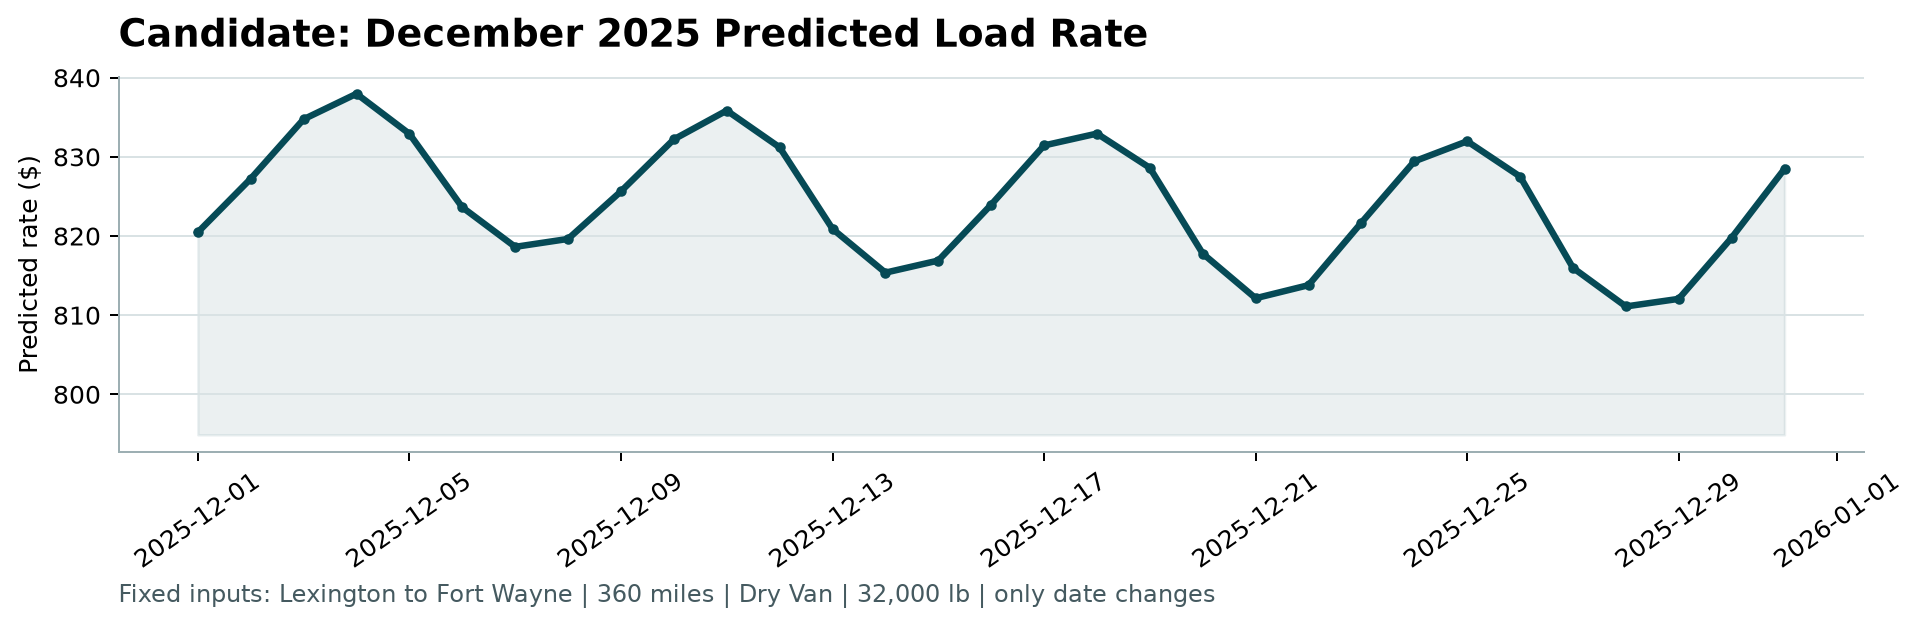

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: d:\projects\SchoolProject\freight-rate-assessment\scorer_results_calibrated\candidate_december.png
Final validation metrics are calculated by Spotter after submission.


In [37]:
run_scorer(ROOT / "validation_predictions_calibrated.csv", ROOT / "december_predictions_calibrated.csv", ROOT / "scorer_results_calibrated")